# 04 · Customer lifetime value (BG/NBD + Gamma-Gamma)
**Business question:** *What is each customer likely to be worth over the next 12 months, and can we trust that number?*

Model: BG/NBD (purchase count + drop-out) × Gamma-Gamma (spend per purchase), implemented from the original papers in `src/cie/clv.py`. CLV = **revenue**, not profit (no cost/margin data), 12-month horizon, 10% annual discount rate (assumption).

In [1]:
import sys, pandas as pd
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from IPython.display import Image, display
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
T = ROOT / 'reports' / 'tables'; F = ROOT / 'reports' / 'figures'
def fig(name): display(Image(filename=str(F / f'{name}.png')))

## 1. Out-of-sample test: calibrate to 9 Jun 2011, predict the next 6 months

In [2]:
pd.read_csv(T / 'clv_validation_summary.csv', index_col=0)

,value
calibration_end,2011-06-09
holdout_days,183
customers,4936
actual_purchases_total,7722.0
bgnbd_pred_purchases_total,7565.737775048217
naive_pred_purchases_total,14167.120343085968
bgnbd_purchase_mae,1.0424539569771092
naive_purchase_mae,1.9088430604922881
actual_revenue_total,4243581.071
model_pred_revenue_total,3591353.9965783944


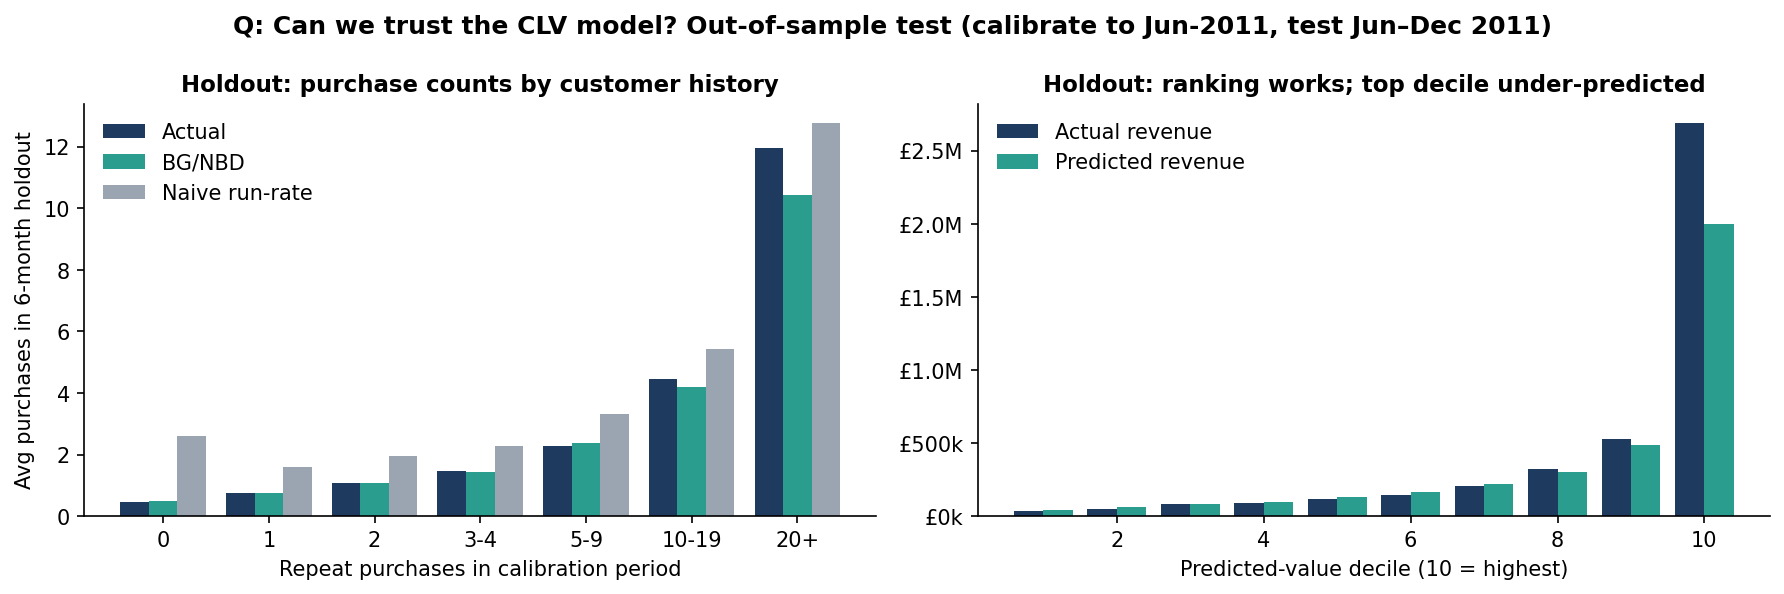

In [3]:
fig('08_clv_validation')

## 2. Direct 12-month backtest (only 12 months of calibration history available)

In [4]:
pd.read_csv(T / 'clv_backtest_12m.csv', index_col=0)

,value
calibration_window,2009-12-01 to 2010-12-09 (12 months)
customers,4274
pred_purchases,18458.042171173198
actual_purchases,12125.0
pred_revenue,8693250.293813016
actual_revenue,6492779.442
revenue_error_pct,0.3389104576044548
bgnbd_b_param,88.27634179269874
spearman_rev,0.5812030968834303


**Read-out — honest assessment**
* **Purchase counts:** BG/NBD predicted 7,566 holdout purchases vs 7,722 actual (−2%); a naive run-rate model predicted 14,167 (+83%).
* **Revenue:** under-predicted by 15% on the 6-month holdout (which contains the Christmas peak).
* **12-month backtest:** with only 12 months of history the model **over-predicted revenue by 34%** — the drop-out parameter cannot be learned from a short, left-censored history.
* **Ranking:** customers the model ranked in the top 20% delivered 76% of actual holdout revenue.

**Conclusion:** use CLV to **rank and prioritise** customers with confidence; treat the absolute £ total as a range, not a point forecast.

In [5]:
pd.read_csv(T / 'clv_assumption_checks.csv')

,check,value,guidance
0,Gamma-Gamma independence: Pearson corr(frequen...,0.142,|r| < 0.3 is usually treated as acceptable
1,Gamma-Gamma independence: Spearman corr(freque...,0.249,rank-based; robust to the very long spend tail
2,Share of customers with zero repeat purchases,0.285,these receive population-average spend


In [6]:
pd.read_csv(T / 'clv_discount_sensitivity.csv')

,annual_discount_rate,total_clv_12m
0,0.000,"8,617,646.666"
1,0.050,"8,395,623.934"
2,0.100,"8,190,764.451"
3,0.150,"8,001,023.660"
4,0.200,"7,824,677.551"


In [7]:
pd.read_csv(T / 'clv_params_final.csv', index_col=0)

,value
r,0.670
alpha,9.187
a,0.109
b,2.354
p,2.197
q,3.600
v,462.671


## What should management do differently?
1. **Allocate retention and service effort by predicted value**, not by last year's revenue alone — the model's ranking is reliable.
2. **Do not put the £ CLV total in a budget as a forecast.** Present it as a range cross-checked against net revenue retention (81%).
3. **Ask Finance for gross margin** by product line; until then, no CLV-based spending limit can be set in profit terms.